# 03 · Site distributions

The geographic distribution of MSHMM sites and their satellite coverage.  

### 1. Load the catalog and summarize sites

Set `DATA_ROOT` to the directory containing `db.xlsx` and the three batch folders.  
Change `DATA_ROOT` with your local data path.

In [1]:
from pathlib import Path
import sys

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebook":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "src"))

from mshmm.catalog import load_catalog
from mshmm.statistics import summarize_sites
from mshmm.plotting import plot_sites

DATA_ROOT = REPO_ROOT.parent  # Change this to your data root.
catalog = load_catalog(DATA_ROOT)
sites = summarize_sites(catalog)

print(f"Sites: {len(sites)}")
print(f"Observations at these sites: {sites['observations'].sum():,}")
display(sites.head())

Sites: 81
Observations at these sites: 463


,lon,lat,name,belonging,type,observations,plume_observations,sensors,sensor_count
0,-103.748,32.219,DCP Midstream oil grid #4,America,oil,5,3,"(GF5, PRS)",2
1,-103.748,32.354,DCP Midstream oil grid #2,America,oil,10,5,"(ENMAP, GF5, PRS)",3
2,-103.748,32.488,DCP Midstream oil grid,America,oil,10,5,"(ENMAP, GF5, PRS)",3
3,-103.588,32.219,DCP Midstream oil grid #5,America,oil,7,5,"(GF5, PRS)",2
4,-103.588,32.354,DCP Midstream oil grid #3,America,oil,11,6,"(ENMAP, GF5, PRS)",3


### 2. Compare site categories

Count sites and observations separately for each source category.  
The same site can contribute many observations, so the two counts describe different aspects of the dataset.

,sites,observations,plume_observations
type,,,
coal,12,66,40
oil,22,152,120
waste,47,245,221


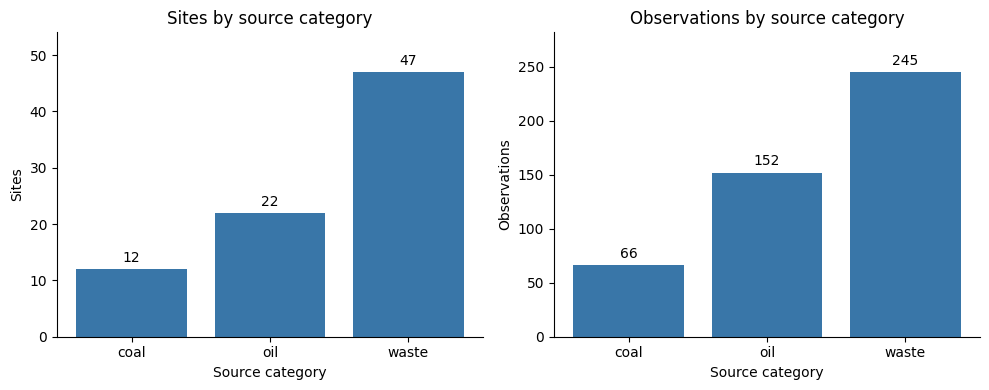

In [2]:
category_summary = sites.groupby("type").agg(
    sites=("name", "size"),
    observations=("observations", "sum"),
    plume_observations=("plume_observations", "sum"),
)
display(category_summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, column in zip(axes, ["sites", "observations"]):
    bars = ax.bar(category_summary.index, category_summary[column], color="#3976a8")
    ax.bar_label(bars, padding=3)
    ax.set_xlabel("Source category")
    ax.set_ylabel(column.capitalize())
    ax.set_title(f"{column.capitalize()} by source category")
    ax.set_ylim(0, category_summary[column].max() * 1.15)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### 3. Map global sites

Each marker represents one site; colors distinguish coal, oil, and waste sources.  
Nearby sites can overlap at this global scale. Legend counts refer to sites, rather than observations.

Cartopy draws land and coastlines using [Natural Earth features](https://cartopy.readthedocs.io/stable/matplotlib/feature_interface.html).  
On first use, Cartopy downloads map data into cache.

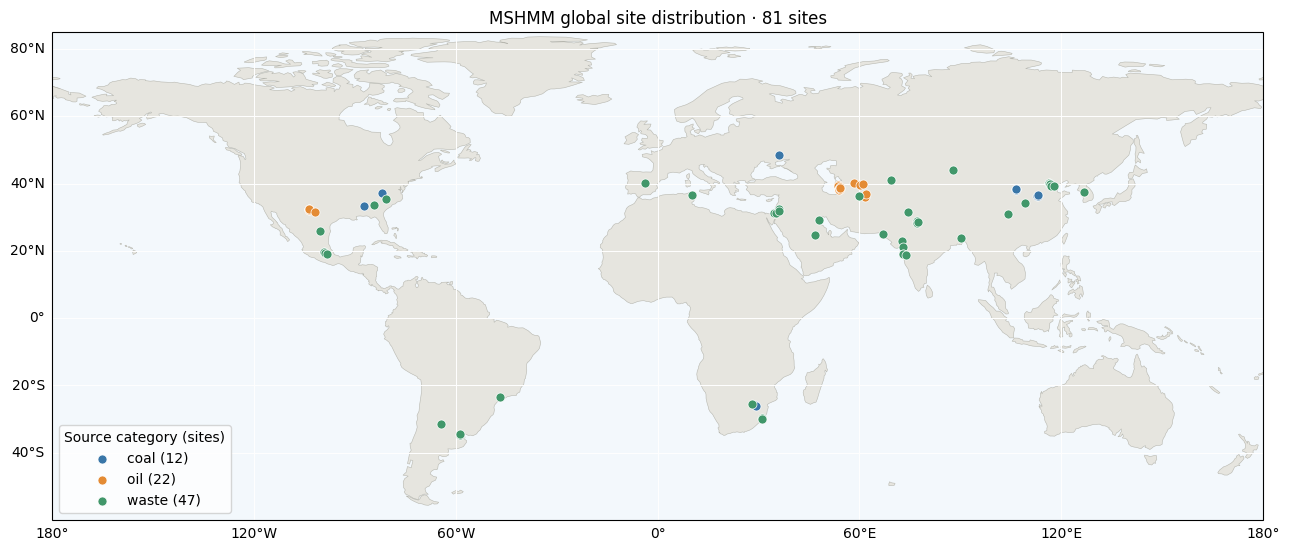

In [3]:
fig, ax = plt.subplots(
    figsize=(13, 6), subplot_kw={"projection": ccrs.PlateCarree()}
)
plot_sites(sites, ax=ax)
ax.set_title(f"MSHMM global site distribution · {len(sites)} sites")
fig.tight_layout()
plt.show()

### 4. Count coverage by satellite

Count each site once for every sensor that observes it.  

,sites,percent_of_sites
sensor,,
EMIT,38,46.91
ENMAP,39,48.15
GF5,54,66.67
PRS,39,48.15


Sites covered by multiple sensors: 62


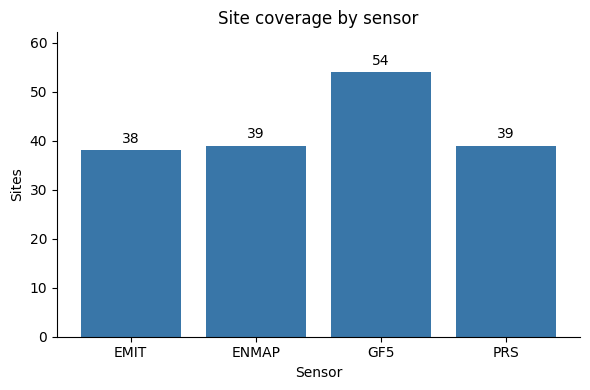

In [4]:
sensor_sites = sites.explode("sensors").rename(columns={"sensors": "sensor"})
coverage = sensor_sites.groupby("sensor").size().rename("sites").to_frame()
coverage["percent_of_sites"] = (coverage["sites"] / len(sites) * 100).round(2)
display(coverage)
print(f"Sites covered by multiple sensors: {(sites['sensor_count'] > 1).sum()}")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(coverage.index, coverage["sites"], color="#3976a8")
ax.bar_label(bars, padding=3)
ax.set_xlabel("Sensor")
ax.set_ylabel("Sites")
ax.set_title("Site coverage by sensor")
ax.set_ylim(0, coverage["sites"].max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### 5. Map coverage for each sensor

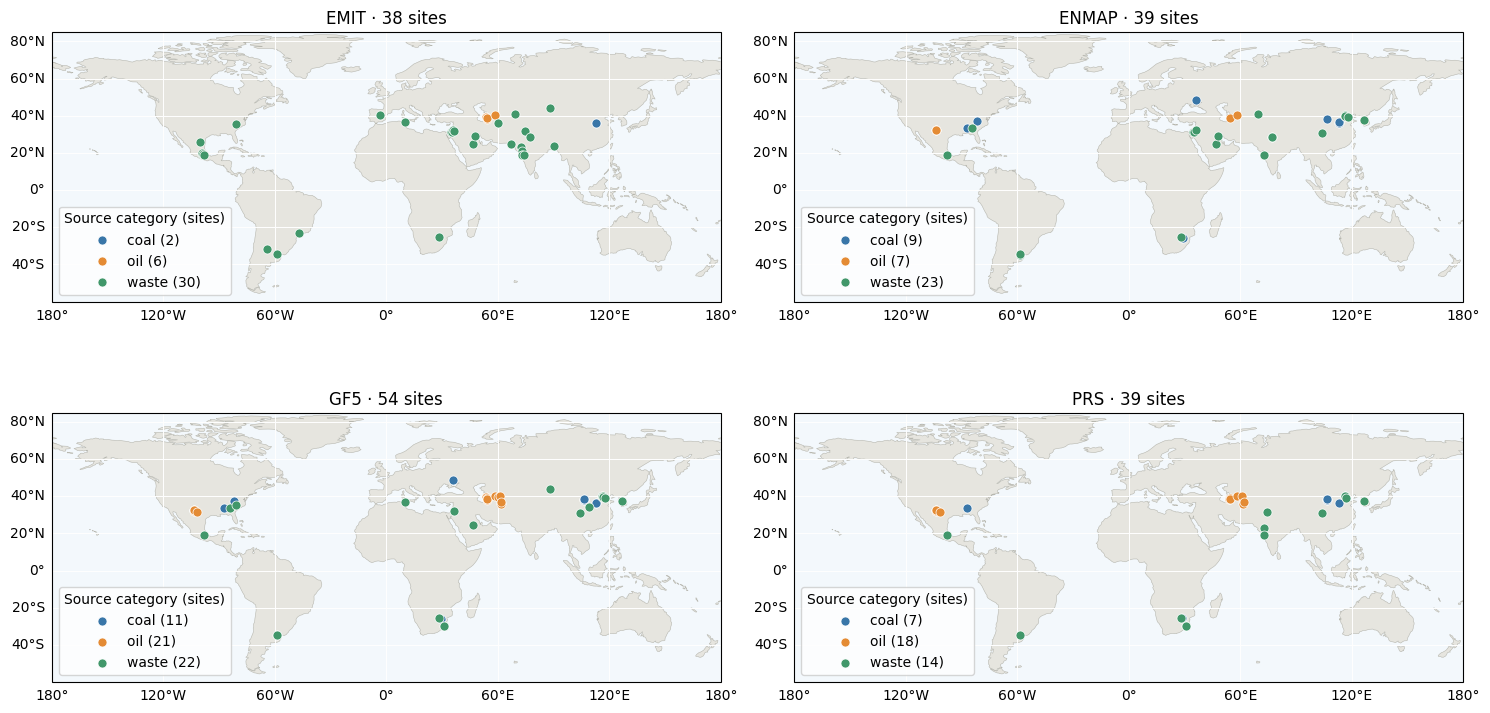

In [5]:
fig, axes = plt.subplots(
    2, 2, figsize=(15, 8), subplot_kw={"projection": ccrs.PlateCarree()}
)
for ax, sensor in zip(axes.flat, coverage.index):
    covered_sites = sensor_sites.loc[sensor_sites["sensor"] == sensor]
    plot_sites(covered_sites, ax=ax)
    ax.set_title(f"{sensor} · {len(covered_sites)} sites")
fig.tight_layout()
plt.show()